ULOADEAD A FILE


In [ ]:
from google.colab import files

uploaded = files.upload()


Saving WA_Fn-UseC_-Telco-Customer-Churn (1).csv to WA_Fn-UseC_-Telco-Customer-Churn (1).csv


TASK 1

In [ ]:
import numpy as np
import pandas as pd

# Load the dataset
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn (1).csv')

# 1. Display dimensions (shape)
print("=== DATASET SHAPE ===")
print(f"Total Rows: {df.shape[0]}, Total Columns: {df.shape[1]}\n")

# 2. Display column names and data types
print("=== COLUMN DATA TYPES ===")
print(df.dtypes)

# 3. Display first 5 rows
print("\n=== FIRST 5 ROWS ===")
display(df.head())

# 4. Check target variable distribution
print("\n=== TARGET VARIABLE (Churn) COUNT ===")
print(df['Churn'].value_counts())

=== DATASET SHAPE ===
Total Rows: 7043, Total Columns: 21

=== COLUMN DATA TYPES ===
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

=== FIRST 5 ROWS ===


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



=== TARGET VARIABLE (Churn) COUNT ===
Churn
No     5174
Yes    1869
Name: count, dtype: int64


TASK 2

In [ ]:

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(), errors="coerce"
)


print("Missing TotalCharges values before fixing:", df["TotalCharges"].isnull().sum())


df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)

df_clean = df.drop(columns=["customerID"])


print("Duplicate records found:", df_clean.duplicated().sum())

print("\nMissing values per column after cleaning:")
print(df_clean.isnull().sum())
print("\nClean Dataset Shape:", df_clean.shape)

Missing TotalCharges values before fixing: 11
Duplicate records found: 22

Missing values per column after cleaning:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Clean Dataset Shape: (7043, 20)


/tmp/ipykernel_3756/1984411192.py:9: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)


TASK 3

/tmp/ipykernel_3756/3000687368.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.countplot(data=df_clean, x="Churn", palette="Set2")


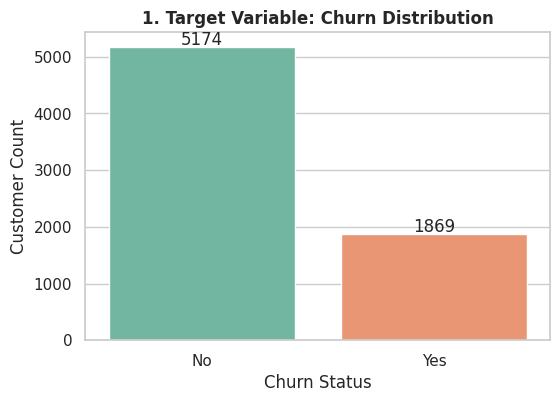

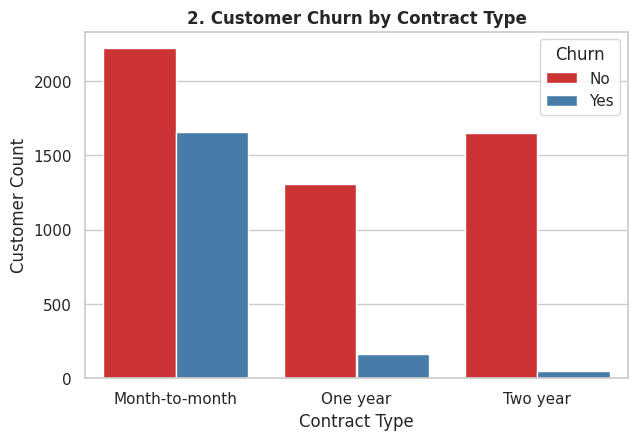

/tmp/ipykernel_3756/3000687368.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x="Churn", y="tenure", palette="Set3")


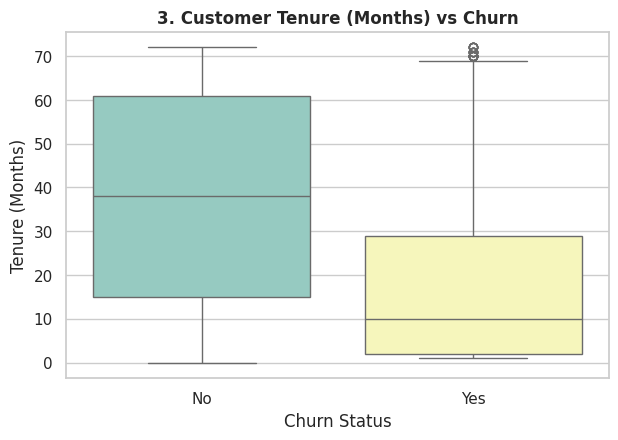

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(6, 4))
ax1 = sns.countplot(data=df_clean, x="Churn", palette="Set2")
plt.title("1. Target Variable: Churn Distribution", fontsize=12, fontweight="bold")
plt.xlabel("Churn Status")
plt.ylabel("Customer Count")
for p in ax1.patches:
    ax1.annotate(
        f"{int(p.get_height())}",
        (p.get_x() + p.get_width() / 2.0, p.get_height()),
        ha="center",
        va="center",
        xytext=(0, 5),
        textcoords="offset points",
    )
plt.savefig("churn_distribution.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4.5))
sns.countplot(data=df_clean, x="Contract", hue="Churn", palette="Set1")
plt.title("2. Customer Churn by Contract Type", fontsize=12, fontweight="bold")
plt.xlabel("Contract Type")
plt.ylabel("Customer Count")
plt.savefig("churn_by_contract.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df_clean, x="Churn", y="tenure", palette="Set3")
plt.title(
    "3. Customer Tenure (Months) vs Churn", fontsize=12, fontweight="bold"
)
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")
plt.savefig("tenure_vs_churn.png", bbox_inches="tight")
plt.show()

TASK 4

In [ ]:



df_clean['Churn'] = df_clean['Churn'].map({'Yes': 1, 'No': 0})

X = df_clean.drop(columns=['Churn'])
y = df_clean['Churn']

X_encoded = pd.get_dummies(X, drop_first=True)

print("=== FEATURE ENGINEERING & ENCODING SUMMARY ===")
print("Original text dataset shape:", X.shape)
print("Encoded features X shape    :", X_encoded.shape)
print("Target label y shape        :", y.shape)

print("\nFirst 5 rows of encoded features X:")
display(X_encoded.head(2))

=== FEATURE ENGINEERING & ENCODING SUMMARY ===
Original text dataset shape: (7043, 19)
Encoded features X shape    : (7043, 30)
Target label y shape        : (7043,)

First 5 rows of encoded features X:


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,False,True,False,False,True,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,True,False,False,True,False,False,...,False,False,False,False,True,False,False,False,False,True


Task 5 & 6 - Model Training, Testing & Evaluation

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd

# Safely reconstruct y since df_clean['Churn'] got corrupted to NaN from double-mapping
if df_clean['Churn'].isnull().all():
    print("Re-aligning target variable 'y' from original dataset...")
    y = df['Churn'].map({'Yes': 1, 'No': 0})
    df_clean['Churn'] = y
else:
    y = df_clean['Churn']

# Ensure X_encoded matches the same clean index
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = []

for name, model in models.items():
    if name == "Logistic Regression":
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)
        preds = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
        'Confusion Matrix': confusion_matrix(y_test, preds)
    })

eval_df = pd.DataFrame(results)
print("MODEL PERFORMANCE COMPARISON:")
display(eval_df[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score']])

for res in results:
    print(f"\n{res['Model']} Confusion Matrix:")
    print(res['Confusion Matrix'])

MODEL PERFORMANCE COMPARISON:


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.806955,0.658385,0.566845,0.609195
1,Decision Tree,0.794180,0.629630,0.545455,0.584527
2,Random Forest,0.786373,0.623729,0.491979,0.550075



Logistic Regression Confusion Matrix:
[[925 110]
 [162 212]]

Decision Tree Confusion Matrix:
[[915 120]
 [170 204]]

Random Forest Confusion Matrix:
[[924 111]
 [190 184]]


TASK 7


In [13]:
best_model = models["Logistic Regression"]
sample_customers = X_test_scaled[:2]

predictions = best_model.predict(sample_customers)
probabilities = best_model.predict_proba(sample_customers)[:, 1]

for i, (pred, prob) in enumerate(zip(predictions, probabilities), 1):
    status = "Yes (Will Churn)" if pred == 1 else "No (Will Remain)"
    print(f"Customer {i}: Prediction = {status} | Churn Risk = {prob:.2%}")

Customer 1: Prediction = No (Will Remain) | Churn Risk = 4.44%
Customer 2: Prediction = Yes (Will Churn) | Churn Risk = 68.36%
